# Plotting Directly with Matplotlib

The same chart types drawn with Matplotlib's object-oriented interface (`fig, ax = plt.subplots()`): line plots with an annotated Haiti earthquake spike, scatter, bar, histogram and pie charts, and a 2×2 grid of subplots.

*Lab from IBM's **Data Visualization with Python** course (Coursera), documented in my own words.*

**Skills:** `plt.subplots`, `ax.set_title` / `set_xlabel`, `ax.annotate`, `set_xticks`, `add_subplot`, `suptitle`

## Load the data

In [1]:
#Import Primary Modules:
import numpy as np  # useful for many scientific computing in Python
import pandas as pd # primary data structure library

# use the inline backend to generate the plots within the browser
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
import requests
import pandas as pd
import io

# Define the URL
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv"

# Send a GET request to the URL
response = requests.get(URL)

# Convert the content into a BytesIO object
text = io.BytesIO(response.content)

# Read the CSV data into a pandas dataframe
df_can = pd.read_csv(text)

# Print confirmation
print('Data read into a pandas dataframe!')

Data read into a pandas dataframe!


In [3]:
df_can.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


In [4]:
# print the dimensions of the dataframe
print(df_can.shape)

(195, 39)


In [5]:
df_can = df_can.set_index('Country')

# Let's view the first five elements and see how the dataframe was changed
df_can.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


In [6]:
print('data dimensions:', df_can.shape)

data dimensions: (195, 38)


In [7]:
# finally, let's create a list of years from 1980 - 2013
# this will come in handy when we start plotting the data
years = list(map(str, range(1980, 2014)))
#years = np.arange(1980,2014)

## Line Plot

In [8]:
#As years is in the array format, you will be required to map it to str for plotting
years = list(map(str, range(1980, 2014)))
#creating df with only years columns from 1980 - 2013
df_line=df_can[years]

#Applying sum to get total immigrants year-wise
total_immigrants=df_line.sum()
total_immigrants

1980     99137
1981    110563
1982    104271
1983     75550
1984     73417
1985     69978
1986     86048
1987    134771
1988    139306
1989    164432
1990    188054
1991    207509
1992    221687
1993    222049
1994    193665
1995    187712
1996    200085
1997    192885
1998    160727
1999    179818
2000    216712
2001    242643
2002    223111
2003    217297
2004    232083
2005    257457
2006    247057
2007    232405
2008    243047
2009    248768
2010    276956
2011    246194
2012    256222
2013    257537
dtype: int64

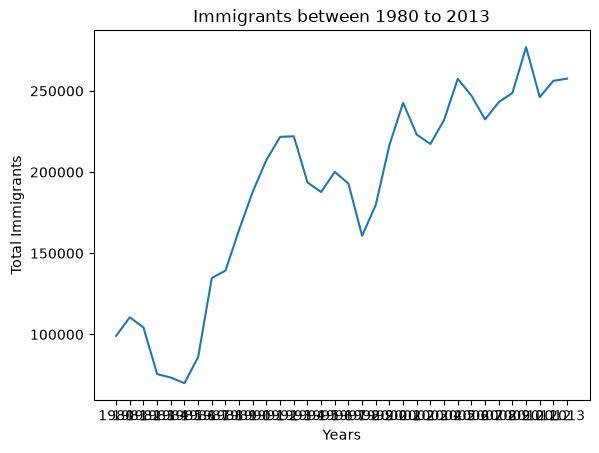

In [9]:
#Create figure and axes
fig, ax = plt.subplots()

# Plot the line
ax.plot(total_immigrants)

#Setting up the Title
ax.set_title('Immigrants between 1980 to 2013') 
#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Total Immigrants')

#Display the plot
plt.show()

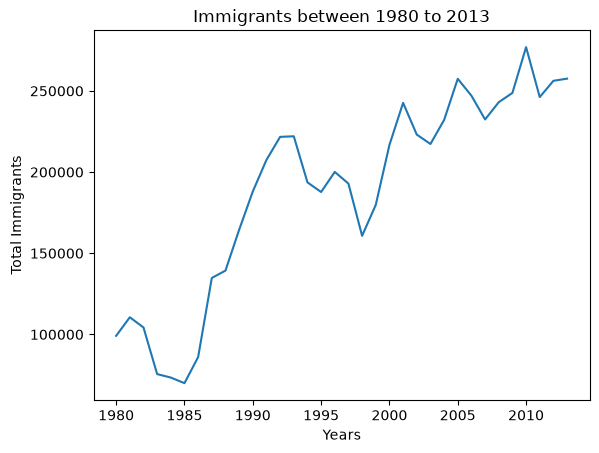

In [10]:
#Create figure and axes
fig, ax = plt.subplots()

#Changing the index type to integer
total_immigrants.index = total_immigrants.index.map(int)

# Plot the line
ax.plot(total_immigrants)

#Setting up the Title
ax.set_title('Immigrants between 1980 to 2013') 

#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Total Immigrants')

#Display the plot
plt.show()

#### Customizing the plot

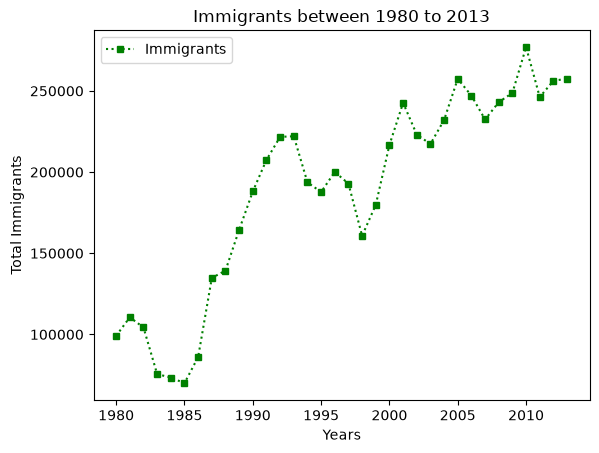

In [11]:
#Create figure and axes
fig, ax = plt.subplots()

# Customizing the appearance of Plot
ax.plot(total_immigrants, 
        marker='s', #Including markers in squares shapes
        markersize=5, #Setting the size of the marker
        color='green', #Changing the color of the line
        linestyle="dotted") #Changing the line style to a Dotted line
#Setting up the Title
ax.set_title('Immigrants between 1980 to 2013') 

#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Total Immigrants')
ax.legend(['Immigrants'])

plt.show()

#### Grid, legend and axis limits

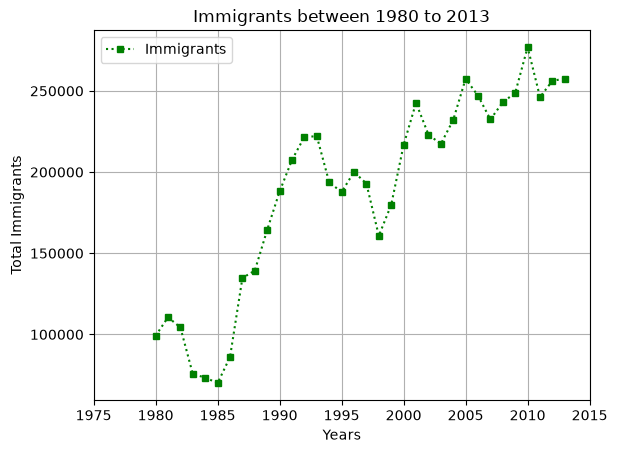

In [12]:
#Create figure and axes
fig, ax = plt.subplots()

# Plot the line
ax.plot(total_immigrants, 
        marker='s', #Including markers in squares shapes
        markersize=5, #Setting the size of the marker
        color='green', #Changing the color of the line
        linestyle="dotted") #Changing the line style to a Dotted line

#Setting up the Title
ax.set_title('Immigrants between 1980 to 2013') 

#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Total Immigrants')

#limits on x-axis
plt.xlim(1975, 2015)  #or ax.set_xlim()

#Enabling Grid
plt.grid(True)  #or ax.grid()

#Legend
plt.legend(["Immigrants"]) #or ax.legend()

#Display the plot
plt.show()

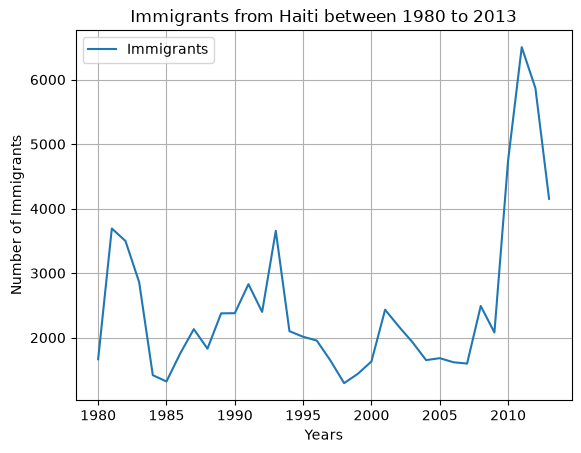

In [13]:
#Creating data for plotting
df_reset = df_can.reset_index()
haiti = df_reset[df_reset['Country'] == 'Haiti']
# creating haiti with only years columns from 1980 - 2013 
# and transposing to get the result as a series
haiti=haiti[years].T.squeeze()

#converting the index to type integer
haiti.index = haiti.index.map(int)
    
#Plotting the line plot on the data
fig, ax = plt.subplots()
ax.plot(haiti)
#Setting up the Title
ax.set_title('Immigrants from Haiti between 1980 to 2013') 
#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Number of Immigrants')
#Enabling Grid
plt.grid(True)  #or ax.grid()
#Legend
plt.legend(["Immigrants"]) #or ax.legend()

#Display the plot
plt.show()

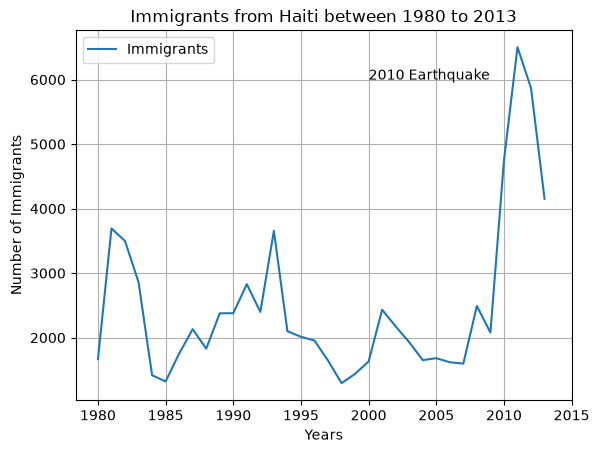

In [14]:
fig, ax = plt.subplots()

ax.plot(haiti)

#Setting up the Title
ax.set_title('Immigrants from Haiti between 1980 to 2013') 

#Setting up the Labels
ax.set_xlabel('Years')
ax.set_ylabel('Number of Immigrants')

#Enabling Grid and ticks
plt.grid(True)  #or ax.grid()
ax.set_xticks(range(1980, 2016, 5))

#Legend
plt.legend(["Immigrants"]) #or ax.legend()

ax.annotate('2010 Earthquake',xy=(2000, 6000))

plt.show()

## Scatter Plot

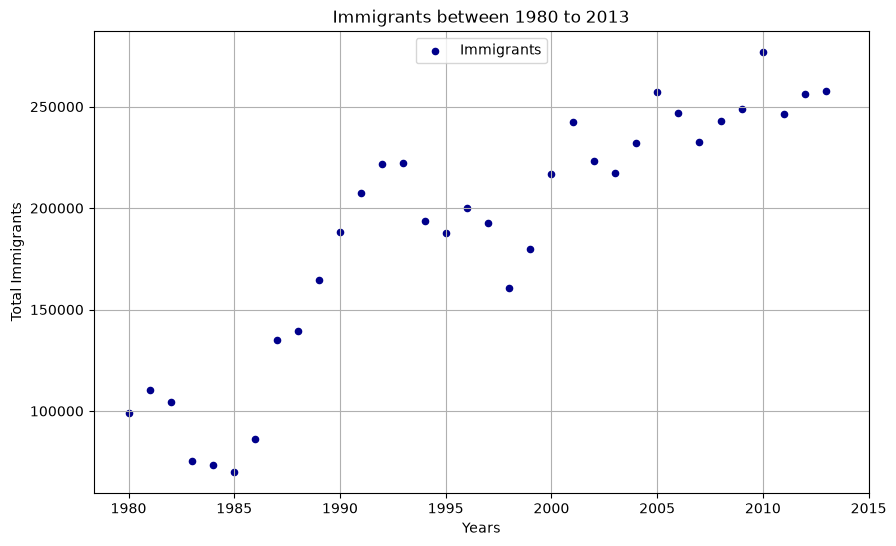

In [15]:
#Create figure and axes
fig, ax = plt.subplots(figsize=(10, 6))
# Customizing Scatter Plot 
ax.scatter(total_immigrants.index, total_immigrants, 
           marker='o', #setting up the markers
           s = 20, #setting up the size of the markers
           color='darkblue')#the color for the marker

#add title 
plt.title('Immigrants between 1980 to 2013') 
#add labels 
plt.xlabel('Years')
plt.ylabel('Total Immigrants') 
#including grid
plt.grid(True)
ax.set_xticks(range(1980, 2016, 5))
#Legend at upper center of the figure
ax.legend(["Immigrants"], loc='upper center')

#Display the plot
plt.show()

## Bar Plot

In [16]:
#Sorting the dataframe on 'Total' in descending order
df_sorted = df_can.sort_values(['Total'], ascending=False)

# get the top 5 entries with head function
df_top5 = df_sorted.head()

#resetting the index back to original way
df_bar_5=df_top5.reset_index()

#Creating a list of names of the top 5 countries
label=list(df_bar_5.Country)
label

['India',
 'China',
 'United Kingdom of Great Britain and Northern Ireland',
 'Philippines',
 'Pakistan']

#### Shortening long labels

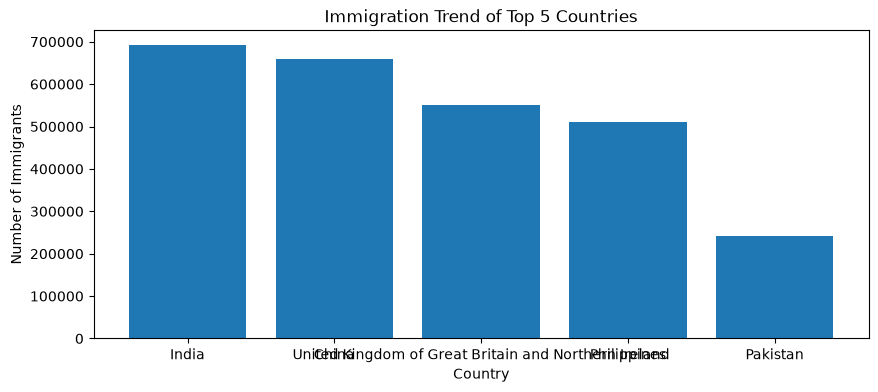

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(label, df_bar_5['Total'], label=label)
ax.set_title('Immigration Trend of Top 5 Countries')
ax.set_ylabel('Number of Immigrants')
ax.set_xlabel('Country')

plt.show()

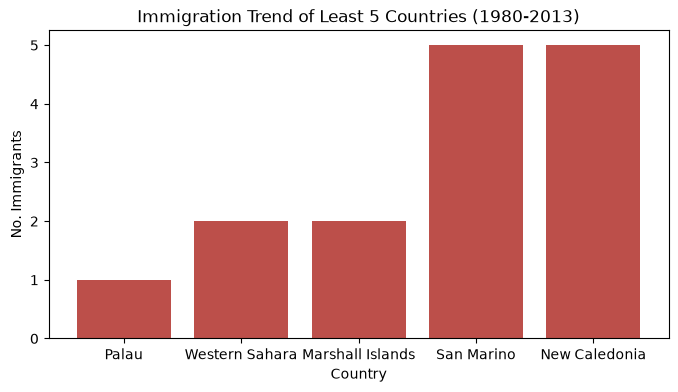

In [18]:
least5 = df_sorted.tail().iloc[::-1].reset_index()
labels=list(least5.Country)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, least5['Total'],label=labels, color='#bc4f4a')
ax.set_title("Immigration Trend of Least 5 Countries (1980-2013)")
ax.set_xlabel("Country")
ax.set_ylabel("No. Immigrants")

plt.show()

## Histogram

In [19]:
df_can.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


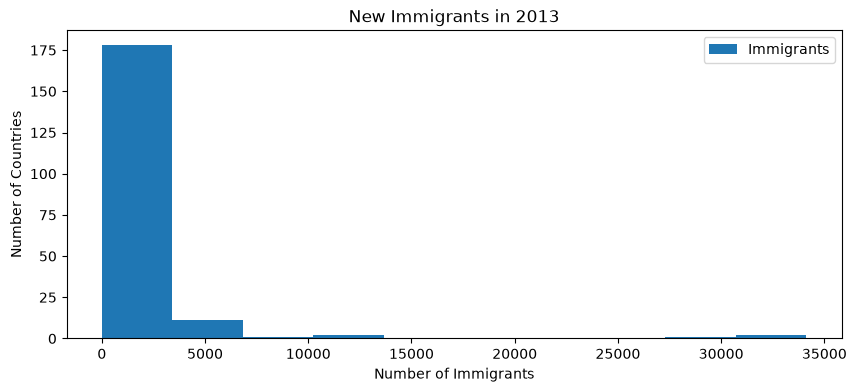

In [20]:
df_country = df_can['2013'].reset_index()

#Create figure and axes
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_country['2013'])
ax.set_title('New Immigrants in 2013') 
ax.set_xlabel('Number of Immigrants')
ax.set_ylabel('Number of Countries')
ax.legend(['Immigrants'])

#Display the plot
plt.show()

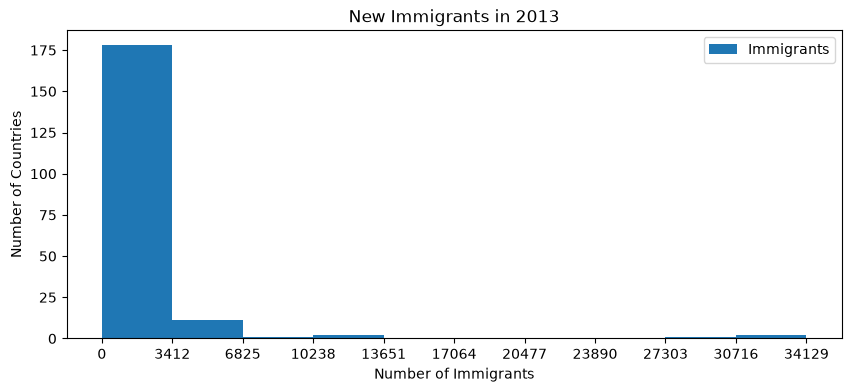

In [21]:
# Plot the bar
fig, ax = plt.subplots(figsize=(10, 4))
count = ax.hist(df_country['2013'])
#you can check the arrays in count with indexing count[0] for count, count[1] for bins

ax.set_title('New Immigrants in 2013') 
ax.set_xlabel('Number of Immigrants')
ax.set_ylabel('Number of Countries')
ax.set_xticks(list(map(int, count[1])))
ax.legend(['Immigrants'])

#Display the plot
plt.show()

In [22]:
# let's quickly view the dataset 
df_dns=df_can.loc[['Denmark', 'Norway', 'Sweden'], years]
df_dns=df_dns.T
df_dns.head()

Country,Denmark,Norway,Sweden
1980,272,116,281
1981,293,77,308
1982,299,106,222
1983,106,51,176
1984,93,31,128


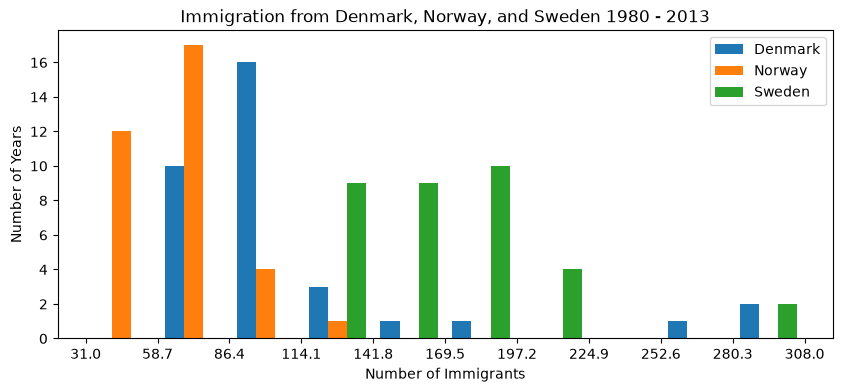

In [23]:
#Create figure and axes
fig, ax = plt.subplots(figsize=(10, 4))
counts = ax.hist(df_dns)
ax.set_title('Immigration from Denmark, Norway, and Sweden 1980 - 2013') 
ax.set_xlabel('Number of Immigrants')
ax.set_ylabel('Number of Years')
ax.set_xticks(counts[1])
ax.legend(['Denmark', 'Norway', 'Sweden'])
#Display the plot
plt.show()

### China vs India, 2000–2013

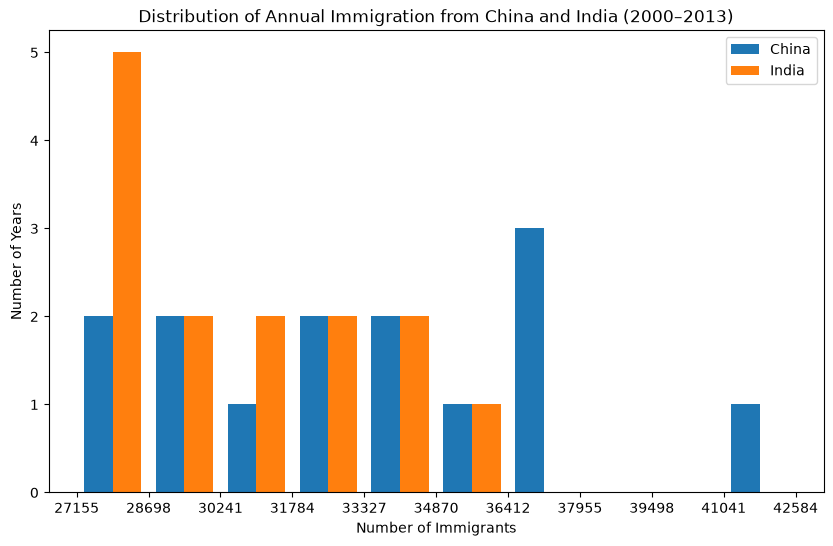

In [24]:
years1 = list(map(str, range(2000, 2014)))
df_ci = df_can.loc[['China', 'India'], years1].T

fig, ax= plt.subplots(figsize=(10, 6))
c = ax.hist(df_ci)

ax.legend(df_ci.columns)
ax.set_title('Distribution of Annual Immigration from China and India (2000–2013)')
ax.set_xlabel("Number of Immigrants")
ax.set_ylabel("Number of Years")
ax.set_xticks(c[1])

plt.show()

## Pie Chart

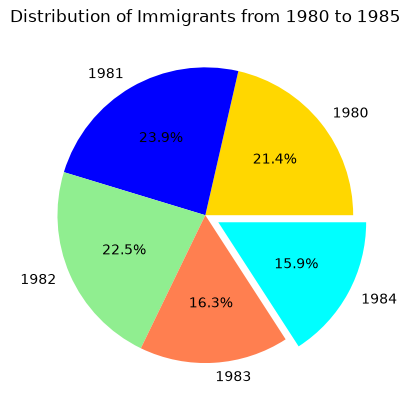

In [25]:
fig, ax=plt.subplots()

#Pie on immigrants
ax.pie(total_immigrants[0:5],
       labels=years[0:5], 
       colors = ['gold','blue','lightgreen','coral','cyan'],
       autopct='%1.1f%%',
       explode = [0,0,0,0,0.1]) #using explode to highlight the lowest 

ax.set_aspect('equal')  # Ensure pie is drawn as a circle

plt.title('Distribution of Immigrants from 1980 to 1985')
#plt.legend(years[0:5]), include legend, if you do not want to pass the labels
plt.show()

In [26]:
#Creating data for plotting pie
df_con = df_can.groupby('Continent')['Total'].sum().reset_index()
label=list(df_con.Continent)
label[3] = 'LAC'
label[4] = 'NA'
df_con

,Continent,Total
0,Africa,618948
1,Asia,3317794
2,Europe,1410947
3,Latin America and the Caribbean,765148
4,Northern America,241142
5,Oceania,55174


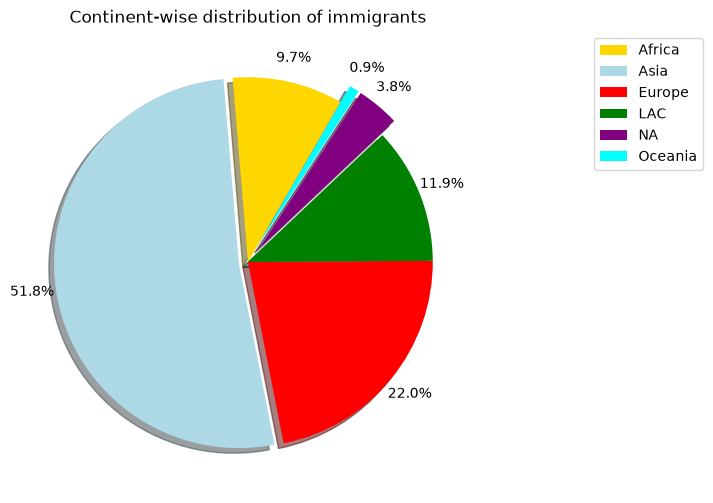

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.pie(df_con['Total'],
       colors=['gold', 'lightblue', 'red', 'green', 'purple', 'cyan'],
       autopct='%1.1f%%',
       pctdistance=1.13,
       explode=[0, 0.05, 0, 0, 0.1, 0.1],
       shadow=True,
       startangle=60
      )
ax.set_title('Continent-wise distribution of immigrants')
ax.set_aspect('equal')
ax.legend(label,bbox_to_anchor=(1, 0, 0.5, 1))

plt.show()

## Sub-plotting

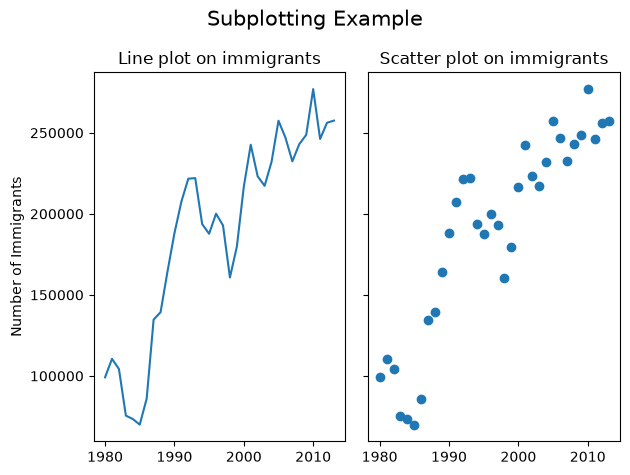

In [28]:
# Create a figure with two axes in a row

fig, axs = plt.subplots(1, 2, sharey=True)

#Plotting in first axes - the left one
axs[0].plot(total_immigrants)
axs[0].set_title("Line plot on immigrants")

#Plotting in second axes - the right one
axs[1].scatter(total_immigrants.index, total_immigrants)
axs[1].set_title("Scatter plot on immigrants")

axs[0].set_ylabel("Number of Immigrants")
            
#Adding a Title for the Overall Figure
fig.suptitle('Subplotting Example', fontsize=15)

# Adjust spacing between subplots
fig.tight_layout()


# Show the figure
plt.show()

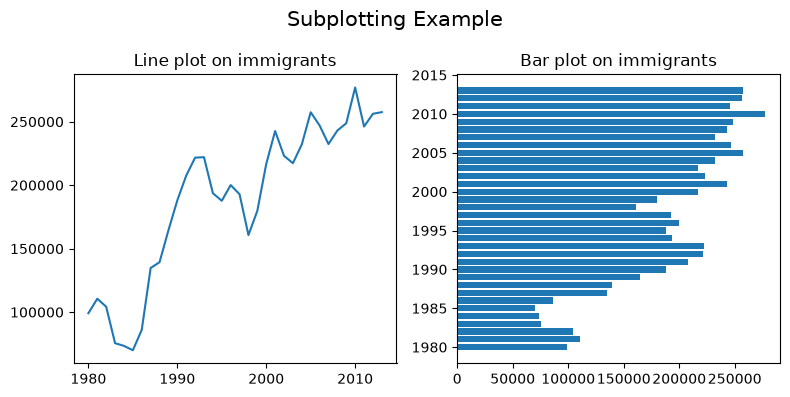

In [29]:
# Create a figure with two axes side by side - one row, two columns
fig = plt.figure(figsize=(8,4))

# Add the first subplot (top-left)
axs1 = fig.add_subplot(1, 2, 1)
#Plotting in first axes - the left one
axs1.plot(total_immigrants)
axs1.set_title("Line plot on immigrants")

# Add the second subplot (top-right)
axs2 = fig.add_subplot(1, 2, 2)
#Plotting in second axes - the right one
axs2.barh(total_immigrants.index, total_immigrants) #Notice the use of 'barh' for creating horizontal bar plot
axs2.set_title("Bar plot on immigrants")
            
#Adding a Title for the Overall Figure
fig.suptitle('Subplotting Example', fontsize=15)

# Adjust spacing between subplots
fig.tight_layout()


# Show the figure
plt.show()

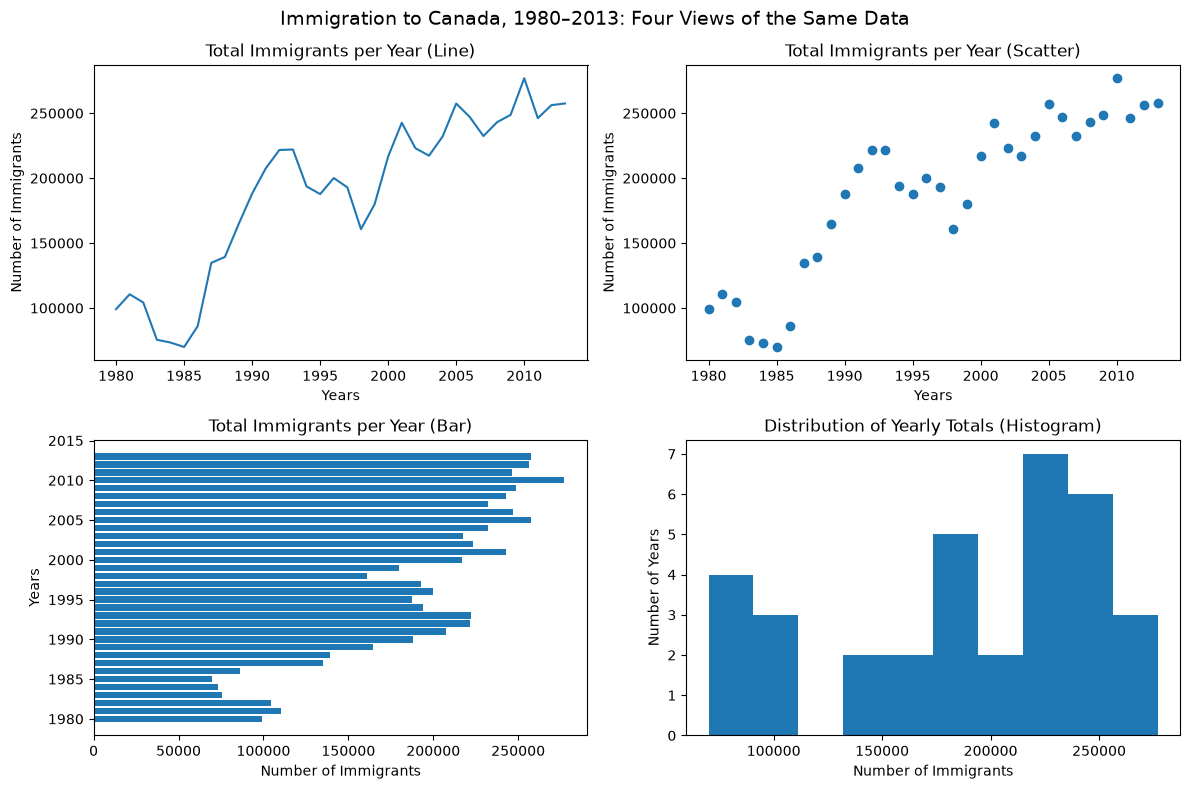

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# ax1
ax[0, 0].plot(total_immigrants)
ax[0, 0].set_title("Total Immigrants per Year (Line)")
ax[0, 0].set_xlabel("Years")
ax[0, 0].set_ylabel("Number of Immigrants")
# ax2
ax[0, 1].scatter(total_immigrants.index, total_immigrants)
ax[0, 1].set_title("Total Immigrants per Year (Scatter)")
ax[0, 1].set_xlabel("Years")
ax[0, 1].set_ylabel("Number of Immigrants")
# ax3
ax[1, 0].barh(total_immigrants.index, total_immigrants)
ax[1, 0].set_title("Total Immigrants per Year (Bar)")
ax[1, 0].set_xlabel("Number of Immigrants")
ax[1, 0].set_ylabel("Years")
# ax4
ax[1, 1].hist(total_immigrants)
ax[1, 1].set_title("Distribution of Yearly Totals (Histogram)")
ax[1, 1].set_xlabel("Number of Immigrants")
ax[1, 1].set_ylabel("Number of Years")


fig.suptitle("Immigration to Canada, 1980–2013: Four Views of the Same Data", fontsize=14)
plt.tight_layout()
plt.show()

## What I took away

- Every chart here goes through a named `ax`, so I always know which chart a command changes. With a grid, `ax[row, col]` picks the chart.
- Years stored as text print every label and tangle the axis. Converting the index to integers gives a number line with neat ticks.
- `ax.hist` already returns the counts and bin edges, so `ax.set_xticks(edges)` lines the labels up without a separate `np.histogram` call.
- In 2013 roughly 91% of countries sent fewer than about 3,400 immigrants each; a handful of countries account for most of the total.
- `add_subplot(rows, cols, position)` counts positions from 1; `plt.subplots(rows, cols)` gives an `ax` grid counted from 0.